# Inspect recordings and mine hard-negative crops
Batch-select full `negative_mining`, hard-negative, or `normal_usage` recordings; mine where **at least one selected model** alarms at its own side thresholds; thin the union across all models to avoid nearby/overlapping crops. The same all-model union is used for the per-file count, one-recording review, and export selection—there is no separate single-model candidate path.

This run uses only `hard_negative_mining_15_10_26/source_recordings/`; crops and provenance go to `hard_negative_mining_15_10_26/crops/`. Previous sources/crops are not included. The previous notebook and model settings are preserved in `mine_hard_negatives_before_15_10_26.ipynb`. Define the new `MODELS` below before mining. Open with the repository `.venv` kernel and run cells in order.

In [81]:
from pathlib import Path
import importlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'tap_recognition').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'tap_recognition').is_dir(), 'Open from repository root or main_notebooks/'
sys.path.insert(0, str(ROOT))
from notebooks_analysis import hard_negative_mining as mining
importlib.reload(mining)
torch.set_num_threads(2)

SOURCE_DIR = ROOT / 'temp'
MINING_WORKSPACE = ROOT / 'hard_negative_mining_15_10_26'
INPUT_DIR = MINING_WORKSPACE / 'source_recordings'
OUTPUT_DIR = MINING_WORKSPACE / 'crops'
STAGE_NEW_RECORDINGS = False  # True to copy SOURCE_DIR; already staged inputs need no copying.

# Define the new model set here; previous models are deliberately not reused.
# Thresholds are manual mining settings, not retuned exports.
MODELS = {
    'latest (1410d8(42))': {
        'checkpoint': ROOT / 'testing_checkpoints/1410d8(42)/best.pt',
        'left_threshold': 0.3, 'right_threshold': 0.3,
    },
    'feature_0910d8(102)': {
        'checkpoint': ROOT / 'testing_checkpoints/lstm64_features/d8(102)/best.pt',
        'left_threshold': 0.95, 'right_threshold': 0.95,
    },
    'raw_0910d8(52)': {
        'checkpoint': ROOT / 'testing_checkpoints/0910d8(52)/best.pt',
        'left_threshold': 0.80, 'right_threshold': 0.80,
    },
}
RESET_AT_SEGMENTS = False  # Continuous through the whole file; always reset between files.


## 1. Stage and inventory inputs
Already staged originals in `INPUT_DIR` need no copying. Enable `STAGE_NEW_RECORDINGS` to copy raw CSVs and existing sparse `.txt` sidecars from `SOURCE_DIR`; identical copies are reused. Inventory includes source type, frames, duration and annotated events. Batch mining accepts negative-only hard-negative and normal_usage originals; a long source stays continuous during inference.

In [82]:
staged = mining.stage_recordings(SOURCE_DIR, INPUT_DIR) if STAGE_NEW_RECORDINGS else []
inventory = mining.recording_inventory(INPUT_DIR)
display(inventory)
models = {name: mining.load_mining_model(spec['checkpoint']) for name, spec in MODELS.items()}
print('Staged:', len(staged), '| models:', ', '.join(models))

,file,user,action,frames,recording_type,seconds,sample_rate_hz,sessions,annotated_events
0,imu_Miguel_negative_mining_20261014_190446.csv,Miguel,negative_mining,20351,hard_negative,203.51,100.0,1,0
1,imu_Miguel_negative_mining_20261015_105147.csv,Miguel,negative_mining,30000,hard_negative,300.00,100.0,1,0
2,imu_Miguel_negative_mining_20261015_105339.csv,Miguel,negative_mining,10303,hard_negative,103.03,100.0,1,0
3,imu_Miguel_negative_mining_20261015_110013.csv,Miguel,negative_mining,13564,hard_negative,135.64,100.0,1,0
4,imu_Miguel_normal_usage_20261014_120217.csv,Miguel,normal_usage,21230,normal_usage,212.30,100.0,1,0
5,imu_Miguel_normal_usage_20261014_121414.csv,Miguel,normal_usage,30002,normal_usage,300.02,100.0,1,0
6,imu_Miguel_normal_usage_20261014_121935.csv,Miguel,normal_usage,30001,normal_usage,300.01,100.0,1,0
7,imu_Miguel_normal_usage_20261014_122459.csv,Miguel,normal_usage,30002,normal_usage,300.02,100.0,1,0
8,imu_Miguel_normal_usage_20261014_122735.csv,Miguel,normal_usage,13711,normal_usage,137.11,100.0,1,0
9,imu_Miguel_normal_usage_20261014_131245.csv,Miguel,normal_usage,14657,normal_usage,146.57,100.0,1,0


Staged: 0 | models: latest (1410d8(42)), feature_0910d8(102), raw_0910d8(52)


## 2. Batch mining: select originals and mine the union of model failures
First choose `BATCH_SOURCE_TYPES=['negative_mining']`, `['normal_usage']`, or both. This filter applies to both `BATCH_SELECT_ALL` and explicit `BATCH_FILES`. Run one type at a time to use different crop duration, context, gap, cooldown or overlap settings: set its `BATCH_*` settings below, mine/export it, then switch types and rerun. Each export records its settings; already exported crops stay in the output folder.

Set `BATCH_FILES` to inventory basenames, or enable `BATCH_SELECT_ALL` for every eligible original of the selected types in the **new workspace only**. Every model keeps its own thresholds from `MODELS`. `BATCH_MIN_GAP_FRAMES` thins the all-model anchor union; `BATCH_ALLOW_OVERLAPPING_CROPS` controls crop intersections. Source copies are deduplicated by hash. Statistics include zero-crop recordings. Short sessions that cannot fit a full crop and candidates whose core would be truncated by training are skipped. Nothing is saved until `SAVE_ALL_BATCH_CROPS=True`.


In [86]:
BATCH_FILES = []  # Explicit new-workspace basenames when BATCH_SELECT_ALL=False.
BATCH_SELECT_ALL = True
BATCH_SOURCE_TYPES = ['normal_usage']  # Choose either type alone for a different cropping style.
BATCH_MODELS = list(MODELS)
BATCH_MIN_GAP_FRAMES = 100
BATCH_ALLOW_OVERLAPPING_CROPS = True
BATCH_CROP_SECONDS = 3.0
BATCH_CONTEXT_BEFORE_SECONDS = 2.5
BATCH_LOOKAHEAD_FRAMES = 0
BATCH_REFRACTORY_FRAMES = 100
BATCH_TRAINING_WINDOW_FRAMES = 300
SAVE_ALL_BATCH_CROPS = True  # True writes every all-model union candidate from this batch.
assert BATCH_MODELS and set(BATCH_MODELS) <= set(models), 'Define MODELS and rerun setup + inventory before mining.'
source_type_aliases = {'negative_mining': 'hard_negative', 'normal_usage': 'normal_usage'}
assert BATCH_SOURCE_TYPES and set(BATCH_SOURCE_TYPES) <= set(source_type_aliases), 'Choose negative_mining and/or normal_usage.'
selected_recording_types = [source_type_aliases[kind] for kind in BATCH_SOURCE_TYPES]
batch_thresholds = {name: (MODELS[name]['left_threshold'], MODELS[name]['right_threshold']) for name in BATCH_MODELS}
eligible = inventory[(inventory.recording_type.isin(selected_recording_types)) &
                     (inventory.annotated_events == 0) & ~inventory.file.str.contains('__crop_', regex=False)]
batch_files = eligible.file.tolist() if BATCH_SELECT_ALL else list(BATCH_FILES)
assert len(batch_files) == len(set(batch_files)) and set(batch_files) <= set(eligible.file), 'Choose eligible original basenames matching BATCH_SOURCE_TYPES'
batch_candidates, batch_file_stats, batch_stats = mining.mine_recordings(
    [INPUT_DIR / file for file in batch_files], {name: models[name] for name in BATCH_MODELS},
    batch_thresholds, min_gap_frames=BATCH_MIN_GAP_FRAMES,
    allow_overlapping_crops=BATCH_ALLOW_OVERLAPPING_CROPS, crop_seconds=BATCH_CROP_SECONDS,
    context_before_seconds=BATCH_CONTEXT_BEFORE_SECONDS, lookahead_frames=BATCH_LOOKAHEAD_FRAMES,
    refractory_frames=BATCH_REFRACTORY_FRAMES, anchor='peak', before_frames=40, after_frames=10,
    training_window_frames=BATCH_TRAINING_WINDOW_FRAMES, reset_at_segments=RESET_AT_SEGMENTS)
display(pd.DataFrame([batch_stats]))
display(batch_file_stats)
display(batch_candidates)
batch_exports = (mining.export_batch(batch_candidates, models, INPUT_DIR, OUTPUT_DIR,
                                    BATCH_TRAINING_WINDOW_FRAMES) if SAVE_ALL_BATCH_CROPS else pd.DataFrame())
if SAVE_ALL_BATCH_CROPS:
    print(f'Exported/reused every batch candidate: {len(batch_exports)} crop(s).')
    display(batch_exports)
if not batch_files: print('Select BATCH_FILES or enable BATCH_SELECT_ALL, then rerun this cell.')


,recordings,crops,recording_minutes,recording_seconds,crop_seconds,crop_minutes,crops_per_minute
0,30,93,119.108333,7146.5,279.0,4.65,0.780802


,file,source_sha256,recording_seconds,recording_minutes,crops,crops_per_minute,crop_seconds,crop_minutes
0,imu_Miguel_normal_usage_20261014_120217.csv,fc4af7fa2a62b6d12e3765dc911066b5a76179a2c59278...,212.30,3.538333,3,0.847857,9.0,0.15
1,imu_Miguel_normal_usage_20261014_121414.csv,c1938c5382b504ec44fe34340c1740057193ac1eee6c63...,300.02,5.000333,2,0.399973,6.0,0.10
2,imu_Miguel_normal_usage_20261014_121935.csv,b389cfaa77f4ae8556ce2bfd7ddd324367e69b4f14ec29...,300.01,5.000167,0,0.000000,0.0,0.00
3,imu_Miguel_normal_usage_20261014_122459.csv,0f9be5edeb3c30553c745c38d963fbbe7944b7e5234219...,300.02,5.000333,6,1.199920,18.0,0.30
4,imu_Miguel_normal_usage_20261014_122735.csv,ab22349d3aa61268abb99e689988dedbc190ddede7f790...,137.11,2.285167,0,0.000000,0.0,0.00
5,imu_Miguel_normal_usage_20261014_131245.csv,0600686f2c040e5fdc65fc85fbf4be91da5276cebddd4d...,146.57,2.442833,7,2.865525,21.0,0.35
6,imu_Miguel_normal_usage_20261014_132558.csv,a6d808bb87fc811e508b97e70a72386db43f6b8002c590...,299.97,4.999500,5,1.000100,15.0,0.25
7,imu_Miguel_normal_usage_20261014_132706.csv,7c436180689d2db1eb83d30f02ee652b4e6d173113d4bf...,23.12,0.385333,0,0.000000,0.0,0.00
8,imu_Miguel_normal_usage_20261014_140005.csv,b326c379554e9ac5b00f19289fdf641ab99061cbc51d5d...,138.68,2.311333,0,0.000000,0.0,0.00
9,imu_Miguel_normal_usage_20261014_144745.csv,4ab05aa3c8dfc6aa28df2f24a989ce383a55f560fcbb67...,300.01,5.000167,1,0.199993,3.0,0.05


,candidate_id,file,source_sha256,model,class_id,side,probability,left_threshold,right_threshold,lookahead_frames,...,core_end_frame,context_clipped,training_retains_core,annotated_events_in_crop,trigger_models,trigger_details,selection_mode,min_gap_frames,allow_overlapping_crops,mining_models
0,0,imu_Miguel_normal_usage_20261014_120217.csv,fc4af7fa2a62b6d12e3765dc911066b5a76179a2c59278...,latest (1410d8(42)),2,right,0.356297,0.3,0.3,0,...,6801,False,True,0,"[latest (1410d8(42)), raw_0910d8(52)]","[{'model': 'latest (1410d8(42))', 'class_id': ...",any_model,100,True,"[{'model': 'latest (1410d8(42))', 'checkpoint_..."
1,1,imu_Miguel_normal_usage_20261014_120217.csv,fc4af7fa2a62b6d12e3765dc911066b5a76179a2c59278...,latest (1410d8(42)),2,right,0.352459,0.3,0.3,0,...,12806,False,True,0,[latest (1410d8(42))],"[{'model': 'latest (1410d8(42))', 'class_id': ...",any_model,100,True,"[{'model': 'latest (1410d8(42))', 'checkpoint_..."
2,2,imu_Miguel_normal_usage_20261014_120217.csv,fc4af7fa2a62b6d12e3765dc911066b5a76179a2c59278...,raw_0910d8(52),2,right,0.840374,0.8,0.8,0,...,20422,False,True,0,[raw_0910d8(52)],"[{'model': 'raw_0910d8(52)', 'class_id': 2, 'p...",any_model,100,True,"[{'model': 'latest (1410d8(42))', 'checkpoint_..."
3,3,imu_Miguel_normal_usage_20261014_121414.csv,c1938c5382b504ec44fe34340c1740057193ac1eee6c63...,latest (1410d8(42)),2,right,0.389889,0.3,0.3,0,...,7080,False,True,0,[latest (1410d8(42))],"[{'model': 'latest (1410d8(42))', 'class_id': ...",any_model,100,True,"[{'model': 'latest (1410d8(42))', 'checkpoint_..."
4,4,imu_Miguel_normal_usage_20261014_121414.csv,c1938c5382b504ec44fe34340c1740057193ac1eee6c63...,latest (1410d8(42)),2,right,0.523651,0.3,0.3,0,...,24501,False,True,0,[latest (1410d8(42))],"[{'model': 'latest (1410d8(42))', 'class_id': ...",any_model,100,True,"[{'model': 'latest (1410d8(42))', 'checkpoint_..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,88,imu_Miguel_normal_usage_20261015_093708.csv,6179cf43a92a276f9cfe724b4b04669cb139aa53908602...,raw_0910d8(52),2,right,0.812701,0.8,0.8,0,...,27543,False,True,0,[raw_0910d8(52)],"[{'model': 'raw_0910d8(52)', 'class_id': 2, 'p...",any_model,100,True,"[{'model': 'latest (1410d8(42))', 'checkpoint_..."
89,89,imu_Miguel_normal_usage_20261015_094214.csv,e6ad9adff89040beb88183efa9103c1cca74d1b825268b...,latest (1410d8(42)),2,right,0.357973,0.3,0.3,0,...,7815,False,True,0,[latest (1410d8(42))],"[{'model': 'latest (1410d8(42))', 'class_id': ...",any_model,100,True,"[{'model': 'latest (1410d8(42))', 'checkpoint_..."
90,90,imu_Miguel_normal_usage_20261015_094214.csv,e6ad9adff89040beb88183efa9103c1cca74d1b825268b...,latest (1410d8(42)),2,right,0.344449,0.3,0.3,0,...,17352,False,True,0,[latest (1410d8(42))],"[{'model': 'latest (1410d8(42))', 'class_id': ...",any_model,100,True,"[{'model': 'latest (1410d8(42))', 'checkpoint_..."
91,91,imu_Miguel_normal_usage_20261015_094214.csv,e6ad9adff89040beb88183efa9103c1cca74d1b825268b...,latest (1410d8(42)),2,right,0.374748,0.3,0.3,0,...,22049,False,True,0,[latest (1410d8(42))],"[{'model': 'latest (1410d8(42))', 'class_id': ...",any_model,100,True,"[{'model': 'latest (1410d8(42))', 'checkpoint_..."


Exported/reused every batch candidate: 93 crop(s).


,candidate_id,csv,label,provenance,frames,seconds,anchor_in_crop,status,file,model,sample_rate_hz
0,0,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_Miguel_normal_usage_20261014_120217.csv,latest (1410d8(42)),100.0
1,1,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_Miguel_normal_usage_20261014_120217.csv,latest (1410d8(42)),100.0
2,2,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_Miguel_normal_usage_20261014_120217.csv,raw_0910d8(52),100.0
3,3,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_Miguel_normal_usage_20261014_121414.csv,latest (1410d8(42)),100.0
4,4,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_Miguel_normal_usage_20261014_121414.csv,latest (1410d8(42)),100.0
...,...,...,...,...,...,...,...,...,...,...,...
88,88,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_Miguel_normal_usage_20261015_093708.csv,raw_0910d8(52),100.0
89,89,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_Miguel_normal_usage_20261015_094214.csv,latest (1410d8(42)),100.0
90,90,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_Miguel_normal_usage_20261015_094214.csv,latest (1410d8(42)),100.0
91,91,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_Miguel_normal_usage_20261015_094214.csv,latest (1410d8(42)),100.0


In [79]:
batch_candidates['model'].value_counts()

model
latest (1410d8(42))    51
raw_0910d8(52)         25
Name: count, dtype: int64

## 3. Review and export one source file using the all-model union
Choose a file from the batch selection below. Its count and table are the exact union that produced `batch_file_stats`: all `BATCH_MODELS` apply their own side thresholds, then the shared gap/overlap rules are applied once. This prevents the old single-model review from showing fewer crops than the per-file batch count.

The whole-recording and crop zoom plots overlay every batch model. `model` is the representative trigger that first kept the candidate; `trigger_models` records every model whose alarm contributed to it. Set `REVIEW_KEEP_IDS` only after reviewing, then enable `SAVE_REVIEWED_CROPS` to write those candidates. To write **every** candidate without review, set `SAVE_ALL_BATCH_CROPS=True` in the batch-mining settings and rerun that cell. Nothing is exported by default.


,file,source_sha256,recording_seconds,recording_minutes,crops,crops_per_minute,crop_seconds,crop_minutes
12,imu_Miguel_normal_usage_20261014_150330.csv,d8008ccb4a72acf4b8fbf7b80b28d53a9dcccf8b411725...,300.03,5.0005,8,1.59984,24.0,0.4


,candidate_id,model,trigger_models,side,probability,anchor_frame,anchor_seconds,crossing_frame,peak_frame,alarm_frame,crop_start_frame,crop_end_frame,crop_seconds,training_retains_core
26,26,latest (1410d8(42)),[latest (1410d8(42))],right,0.33578,1264,12.64,1264,1264,1264,1014,1314,3.0,True
27,27,latest (1410d8(42)),[latest (1410d8(42))],right,0.315236,3220,32.2,3220,3220,3220,2970,3270,3.0,True
28,28,latest (1410d8(42)),"[latest (1410d8(42)), raw_0910d8(52)]",right,0.381205,3691,36.91,3691,3691,3691,3441,3741,3.0,True
29,29,raw_0910d8(52),[raw_0910d8(52)],right,0.835968,9212,92.12,9212,9212,9212,8962,9262,3.0,True
30,30,latest (1410d8(42)),[latest (1410d8(42))],left,0.341736,10276,102.76,10276,10276,10276,10026,10326,3.0,True
31,31,latest (1410d8(42)),[latest (1410d8(42))],right,0.385637,20029,200.29,20029,20029,20029,19779,20079,3.0,True
32,32,raw_0910d8(52),[raw_0910d8(52)],right,0.883231,20095,200.95,20095,20095,20095,19845,20145,3.0,True
33,33,latest (1410d8(42)),[latest (1410d8(42))],left,0.347124,25127,251.27,25127,25127,25127,24877,25177,3.0,True


imu_Miguel_normal_usage_20261014_150330.csv: 8 all-model union candidates; 0 selected for export.


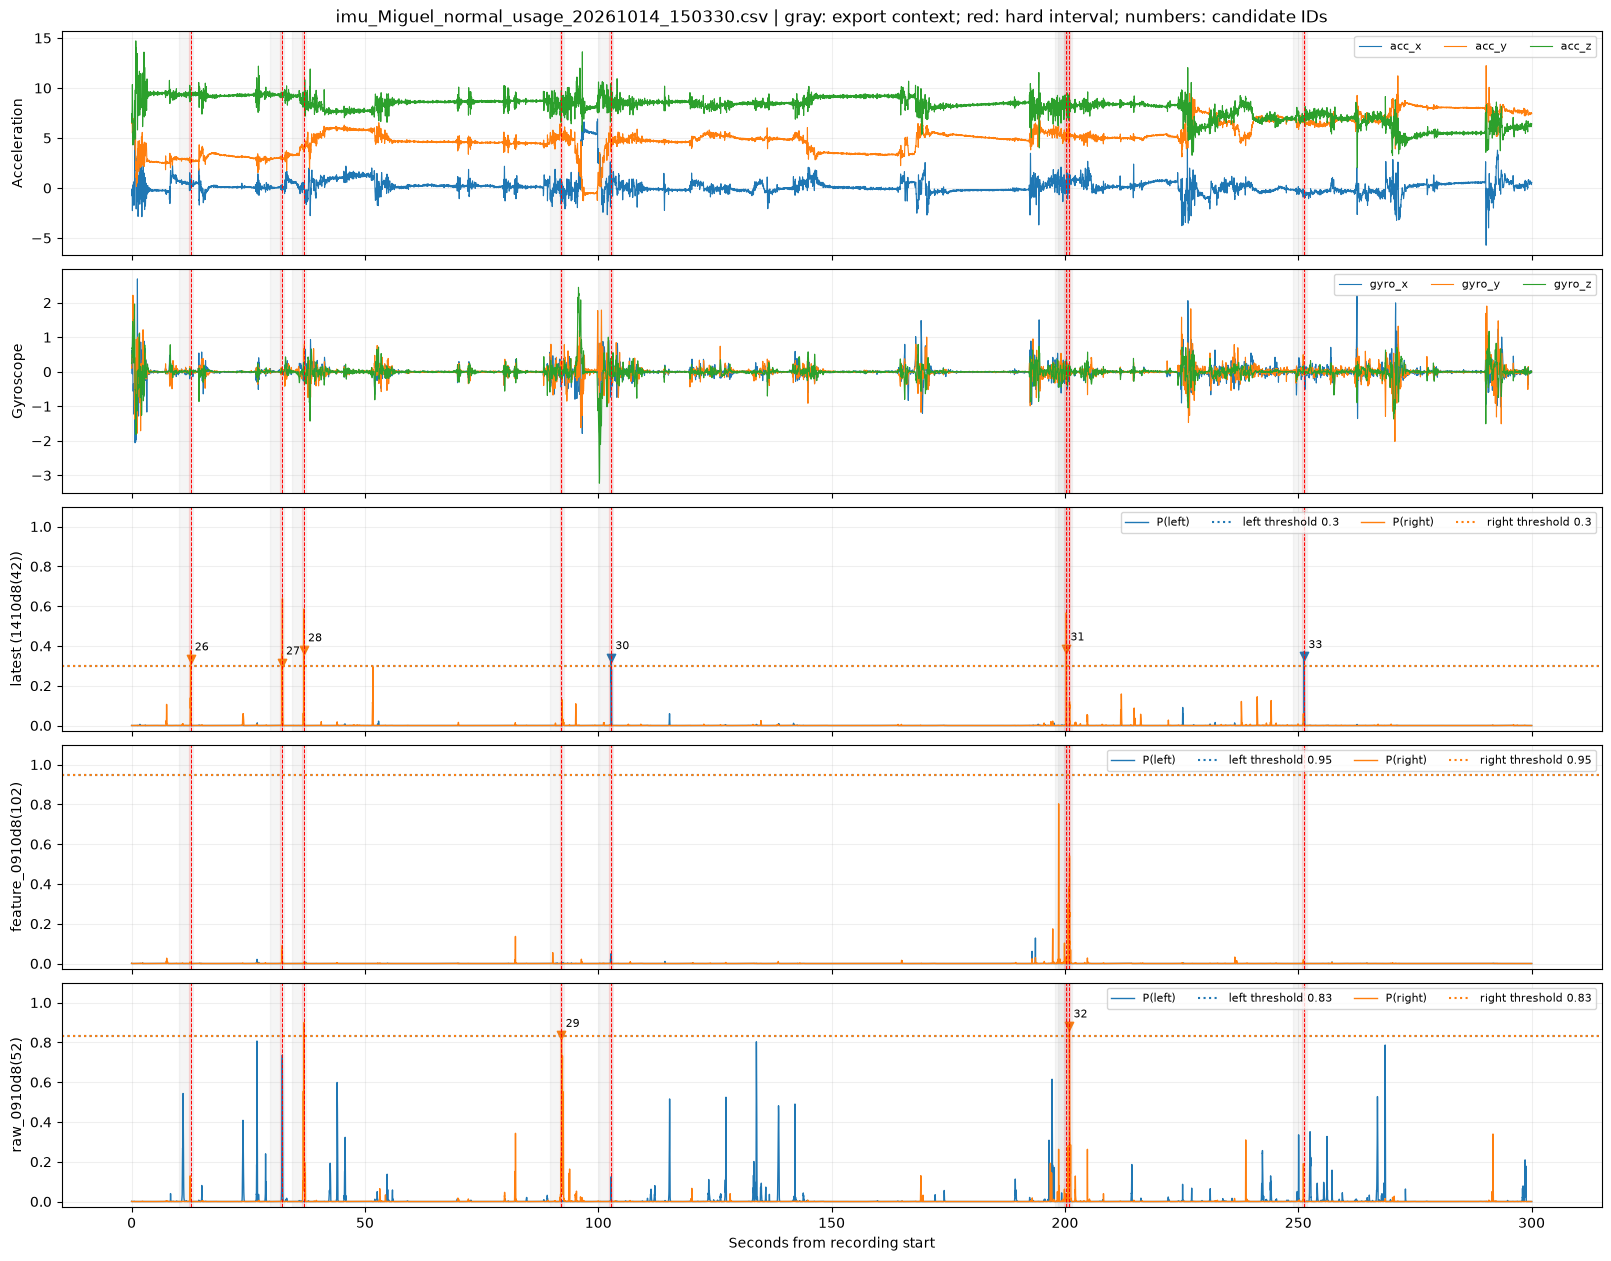

""


Crops currently in /home/aprohack/desktop/work/tap-project/project/tapRecognitionRui/TapRecognition/hard_negative_mining_15_10_26/crops


,file,user,action,frames,recording_type,seconds,sample_rate_hz,sessions,annotated_events
0,imu_Miguel_negative_mining_20261014_190446__cr...,Miguel,negative_mining,300,hard_negative,3.0,100.0,1,0
1,imu_Miguel_negative_mining_20261014_190446__cr...,Miguel,negative_mining,300,hard_negative,3.0,100.0,1,0
2,imu_Miguel_negative_mining_20261014_190446__cr...,Miguel,negative_mining,300,hard_negative,3.0,100.0,1,0
3,imu_Miguel_negative_mining_20261014_190446__cr...,Miguel,negative_mining,300,hard_negative,3.0,100.0,1,0
4,imu_Miguel_negative_mining_20261014_190446__cr...,Miguel,negative_mining,300,hard_negative,3.0,100.0,1,0
...,...,...,...,...,...,...,...,...,...
92,imu_Miguel_negative_mining_20261015_105339__cr...,Miguel,negative_mining,300,hard_negative,3.0,100.0,1,0
93,imu_Miguel_negative_mining_20261015_105339__cr...,Miguel,negative_mining,300,hard_negative,3.0,100.0,1,0
94,imu_Miguel_negative_mining_20261015_105339__cr...,Miguel,negative_mining,300,hard_negative,3.0,100.0,1,0
95,imu_Miguel_negative_mining_20261015_110013__cr...,Miguel,negative_mining,300,hard_negative,3.0,100.0,1,0


In [80]:
# This file must be included by BATCH_FILES/BATCH_SELECT_ALL above.
# REVIEW_FILE = next(iter(batch_files), None)  # Or choose a basename from the current batch.
REVIEW_FILE = 'imu_Miguel_normal_usage_20261014_150330.csv'
REVIEW_CANDIDATE_ID = None  # Global candidate ID; None displays the full all-model union.
REVIEW_KEEP_IDS = []  # Global candidate IDs to export; [] prevents accidental saving.
SAVE_REVIEWED_CROPS = False
FULL_INFERENCE_CHUNK_FRAMES = 4096

assert REVIEW_FILE in set(batch_files), 'Choose a file included in the batch selection, then rerun the batch-mining cell.'
review_candidates = batch_candidates[batch_candidates.file == REVIEW_FILE].copy()
review_stats = batch_file_stats[batch_file_stats.file == REVIEW_FILE]
assert len(review_stats) == 1
assert len(REVIEW_KEEP_IDS) == len(set(REVIEW_KEEP_IDS))
assert set(REVIEW_KEEP_IDS) <= set(review_candidates.candidate_id), 'Unknown candidate ID; rerun batch mining.'
if REVIEW_CANDIDATE_ID is not None:
    assert REVIEW_CANDIDATE_ID in set(review_candidates.candidate_id), 'Unknown candidate ID; rerun batch mining.'

REVIEW_COLUMNS = ['candidate_id', 'model', 'trigger_models', 'side', 'probability',
                  'anchor_frame', 'anchor_seconds', 'crossing_frame', 'peak_frame',
                  'alarm_frame', 'crop_start_frame', 'crop_end_frame', 'crop_seconds',
                  'training_retains_core']
display(review_stats)
display(review_candidates[REVIEW_COLUMNS])
print(f'{REVIEW_FILE}: {len(review_candidates)} all-model union candidates; '
      f'{len(REVIEW_KEEP_IDS)} selected for export.')

recording = mining.load_recording(INPUT_DIR / REVIEW_FILE)
review_traces = {name: mining.predict_recording(recording, models[name], RESET_AT_SEGMENTS,
                                                 FULL_INFERENCE_CHUNK_FRAMES)
                 for name in BATCH_MODELS}
mining.plot_recording(recording, review_traces, batch_thresholds, review_candidates)
plt.show()

if REVIEW_CANDIDATE_ID is not None:
    preview = review_candidates[review_candidates.candidate_id == REVIEW_CANDIDATE_ID]
    row = preview.iloc[0]
    display(preview[REVIEW_COLUMNS])
    mining.plot_recording(recording, review_traces, batch_thresholds, preview,
                          int(row.crop_start_frame), int(row.crop_end_frame))
    plt.show()

reviewed = review_candidates[review_candidates.candidate_id.isin(REVIEW_KEEP_IDS)].copy()
exports = (mining.export_batch(reviewed, models, INPUT_DIR, OUTPUT_DIR,
                                BATCH_TRAINING_WINDOW_FRAMES)
           if SAVE_REVIEWED_CROPS else pd.DataFrame())
display(exports)
print('Crops currently in', OUTPUT_DIR)
display(mining.recording_inventory(OUTPUT_DIR))
